# GL (G-mode + Lloyd) μ*=0.1 optimization runs — set B (TiNbZrHfTaMoWYReRu)

Runs in `opt.ratios.gl/` (Topola, 2026-10-28/29), init database `databases/sra.TiNbZrHfTaMoWYReRu.kp10.ew0.6.gl.csv`
(1795 entries, all recomputed in GL: η from the GG surface formula with MT step + Lloyd-normalised N(E_F)).

* target `Tc_mu0.1` (McMillan, μ* = 0.1 — the value calibrated on the GL literature baseline, median Tc_calc/Tc_exp ≈ 1.05),
  θ_D = mixture Debye, Stoner penalty off, `max_composition = 0.7`, `champions_per_step = 10`, seed 100;
* **mincomp series** `mincomp2..10`, β = 2 (sections 1–9);
* **interior** runs `mincomp2/3` started from `...gl.interior.csv` (998 entries, no face/edge points) — section 10;
* **β scan** at `mincomp7`: β = 0, 1, 2, 5, 10 — section 11;
* **comparison with the previous (A-mode, no Lloyd, μ* = 0.2, max 0.75) runs** in `opt.ratios.mix/` — section 12.
* **bcc / fcc / hcp energies and ΔH of the mincomp-series champions** (Topola, `thermodynamic/`) — section 13.

A composition *counts* for a run only if it has ≥ N elements with fraction > 0.05 (rule of `utils.log_iteration_summary`).
KKR results are read straight from `iteration_*/computation.tar` (`--pack_iterations`); no unpacking needed.
The last iteration of runs that were still running when copied has an empty `computation/` and is skipped.

In [1]:
from pathlib import Path
import json, re, tarfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = Path('../opt.ratios.gl')
BASE_OLD = Path('../opt.ratios.mix')
TARGET = 'Tc_mu0.1'
TARGET_OLD = 'Tc_mu0.2'
RATIO = 0.05
ELEMENTS = ['Ti', 'Nb', 'Zr', 'Hf', 'Ta', 'Mo', 'W', 'Y', 'Re', 'Ru']
EL_COLORS = dict(zip(ELEMENTS, plt.cm.tab10.colors))
pd.set_option('display.width', 250, 'display.max_columns', 40)

In [2]:
def parse_name(name):
    return {el: float(x) for el, x in re.findall(r'([A-Z][a-z]?)(\d+\.\d+)', name)}


def n_comp(row):
    return int(sum(row.get(el, 0.0) > RATIO for el in ELEMENTS))


def comp_str(row, thr=0.005):
    parts = [(el, row[el]) for el in ELEMENTS if row.get(el, 0.0) > thr]
    return ' '.join(f'{el}{100*v:.0f}' for el, v in sorted(parts, key=lambda p: -p[1]))


def iter_results(it_dir):
    # yields (results, selection_info) from computation.tar or from unpacked computation/
    tf = it_dir / 'computation.tar'
    if tf.exists():
        with tarfile.open(tf) as t:
            sel, res = {}, {}
            for m in t.getmembers():
                key = m.name.rstrip('/').split('/')[-2] if '/' in m.name.rstrip('/') else None
                if m.name.endswith('results.json'):
                    res[key] = json.load(t.extractfile(m))
                elif m.name.endswith('selection_info.json'):
                    sel[key] = json.load(t.extractfile(m))
            for k, r in res.items():
                yield r, sel.get(k, {})
        return
    for c in (it_dir / 'computation').glob('*'):
        rf, sf = c / 'results.json', c / 'selection_info.json'
        if rf.exists():
            yield json.loads(rf.read_text()), (json.loads(sf.read_text()) if sf.exists() else {})


def load_run(run_dir, target):
    params = json.loads((run_dir / 'parameters.json').read_text())
    mc = params['min_components']
    beta = float(params.get('acquisition_beta', np.nan))
    interior = '.interior.' in run_dir.name

    init = pd.read_csv(run_dir / 'init_tc_comparison.csv')
    comps = pd.DataFrame([parse_name(n) for n in init['name']]).reindex(columns=ELEMENTS).fillna(0.0)
    init = pd.concat([comps, init[[f'{target}_computed']].rename(columns={f'{target}_computed': 'Tc'})], axis=1)
    init['iteration'] = 0
    init['source'] = 'init'

    rows = []
    for it_dir in run_dir.glob('iteration_*'):
        it = int(it_dir.name.split('_')[1])
        for r, s in iter_results(it_dir):
            row = {el: r.get(el, 0.0) for el in ELEMENTS}
            row.update(iteration=it, source=s.get('source', '?'), Tc=r.get(target),
                       lam=r.get('lambda'), theta=r.get('thetaDB_K'), eta=r.get('eta_mix'), VEC=r.get('VEC'),
                       pred=s.get('pred_target'), pred_std=s.get('pred_target_std'),
                       dist=s.get('composition_distance'))
            rows.append(row)
    opt = pd.DataFrame(rows).sort_values('iteration').reset_index(drop=True)

    df = pd.concat([init, opt], ignore_index=True)
    df['n_comp'] = df.apply(n_comp, axis=1)
    df['valid'] = df['n_comp'] >= mc
    df['comp'] = df.apply(comp_str, axis=1)
    df['mincomp'] = mc
    df['acqbeta'] = beta
    label = f'mc{mc}' + (' int' if interior else '') + ('' if beta == 2 else f' β={beta:g}')
    df['run'] = label

    log = (run_dir / 'optimization_log.txt').read_text()
    m = re.search(r'EARLY STOP after iteration (\d+)', log)
    status = f'early stop @ {m.group(1)}' if m else 'no early stop (still running)'
    n_done = int(opt['iteration'].nunique())
    gaps = sorted(set(range(1, int(opt['iteration'].max()) + 1)) - set(opt['iteration'].unique()))
    if gaps:
        status += f', iteration(s) {gaps} lost (OOM before the fix)'
    return dict(mc=mc, beta=beta, interior=interior, label=label, params=params, df=df,
                status=status, n_iter=int(opt['iteration'].max()), n_done=n_done)


runs_all = sorted((load_run(d, TARGET) for d in BASE.glob('sra.TiNbZrHfTaMoWYReRu.*mincomp*') if d.is_dir()),
                  key=lambda r: (r['interior'], r['mc'], r['beta']))
runs = [r for r in runs_all if r['beta'] == 2 and not r['interior']]       # mincomp series
runs_int = [r for r in runs_all if r['interior']]                           # interior init
runs_beta = [r for r in runs_all if r['mc'] == 7 and not r['interior']]     # β scan
ALL = pd.concat([r['df'] for r in runs], ignore_index=True)
ALLB = pd.concat([r['df'] for r in runs_beta], ignore_index=True)
for r in runs_all:
    d = r['df']
    print(f"{r['label']:>14}: init={int((d.iteration==0).sum())} (valid {int(((d.iteration==0)&d.valid).sum())}), "
          f"opt={int((d.iteration>0).sum())}, iterations done={r['n_done']} (last {r['n_iter']}), {r['status']}")

           mc2: init=1707 (valid 1707), opt=180, iterations done=18 (last 18), early stop @ 18
           mc3: init=1707 (valid 1668), opt=220, iterations done=22 (last 22), early stop @ 22
           mc4: init=1707 (valid 1577), opt=220, iterations done=22 (last 22), early stop @ 22
           mc5: init=1707 (valid 1437), opt=280, iterations done=28 (last 28), early stop @ 28
           mc6: init=1707 (valid 1156), opt=470, iterations done=47 (last 48), early stop @ 48, iteration(s) [30] lost (OOM before the fix)
       mc7 β=0: init=1707 (valid 738), opt=300, iterations done=30 (last 31), early stop @ 31, iteration(s) [30] lost (OOM before the fix)
       mc7 β=1: init=1707 (valid 738), opt=400, iterations done=40 (last 41), early stop @ 41, iteration(s) [30] lost (OOM before the fix)
           mc7: init=1707 (valid 738), opt=440, iterations done=44 (last 44), early stop @ 44
       mc7 β=5: init=1707 (valid 738), opt=220, iterations done=22 (last 22), early stop @ 22
      mc7 β=10

## 1. Summary table — best valid composition per run (mincomp series, β = 2)

In [3]:
def summary(rs, key='mincomp'):
    out = []
    for r in rs:
        d = r['df']; v = d[d.valid]
        i0, io = v[v.iteration == 0], v[v.iteration > 0]
        best = v.loc[v.Tc.idxmax()]
        out.append({key: r['mc'] if key == 'mincomp' else r[key], 'iters': r['n_done'], 'status': r['status'],
                    'n_init_valid': len(i0), 'init_best': i0.Tc.max(), 'opt_best': io.Tc.max(),
                    'gain_K': io.Tc.max() - i0.Tc.max(), 'best_iter': int(best.iteration),
                    'frac_new_valid': d[d.iteration > 0].valid.mean(),
                    'champion': best.comp, 'n_el': int(best.n_comp),
                    'lam': best.lam, 'theta': best.theta, 'VEC': best.VEC})
    return pd.DataFrame(out).set_index(key)

FMT = {'init_best': '{:.2f}', 'opt_best': '{:.2f}', 'gain_K': '{:+.2f}', 'frac_new_valid': '{:.0%}',
       'lam': '{:.2f}', 'theta': '{:.0f}', 'VEC': '{:.2f}'}
summ = summary(runs)
summ.style.format(FMT, na_rep='—')

,iters,status,n_init_valid,init_best,opt_best,gain_K,best_iter,frac_new_valid,champion,n_el,lam,theta,VEC
mincomp,,,,,,,,,,,,,
2,18,early stop @ 18,1707,18.78,18.99,+0.21,3,100%,Nb59 Zr41,2,1.14,273,4.59
3,22,early stop @ 22,1668,13.30,17.92,+4.63,7,100%,Nb56 Zr39 Ta5,3,1.10,271,4.61
4,22,early stop @ 22,1577,12.96,16.60,+3.64,7,100%,Nb56 Zr34 Hf5 Ta5,4,1.04,270,4.61
5,28,early stop @ 28,1437,10.60,14.99,+4.39,13,100%,Nb53 Zr31 Ta6 Ti5 Hf5,5,0.96,278,4.59
6,47,"early stop @ 48, iteration(s) [30] lost (OOM before the fix)",1156,10.60,13.52,+2.91,33,100%,Nb47 Zr33 Ta5 Hf5 Mo5 Ti5,6,0.89,286,4.62
7,44,early stop @ 44,738,5.62,11.92,+6.30,29,100%,Nb53 Zr21 Y6 Ta5 Hf5 Ti5 Mo5,7,0.83,287,4.62
8,25,early stop @ 25,361,3.81,9.73,+5.91,10,100%,Nb58 Y7 W7 Ta6 Zr6 Hf6 Ti5 Mo5,8,0.74,297,4.81
9,24,early stop @ 24,130,3.15,7.22,+4.07,9,100%,Nb45 Zr14 Hf8 Ta7 Ti6 W5 Re5 Y5 Mo5,9,0.65,301,4.82
10,23,early stop @ 23,3,0.46,4.36,+3.89,8,100%,Zr41 Nb15 Ta6 Ti6 Hf6 Y5 Re5 Ru5 W5 Mo5,10,0.54,317,4.72


## 2. Convergence — best-so-far (valid only) and all new points per iteration

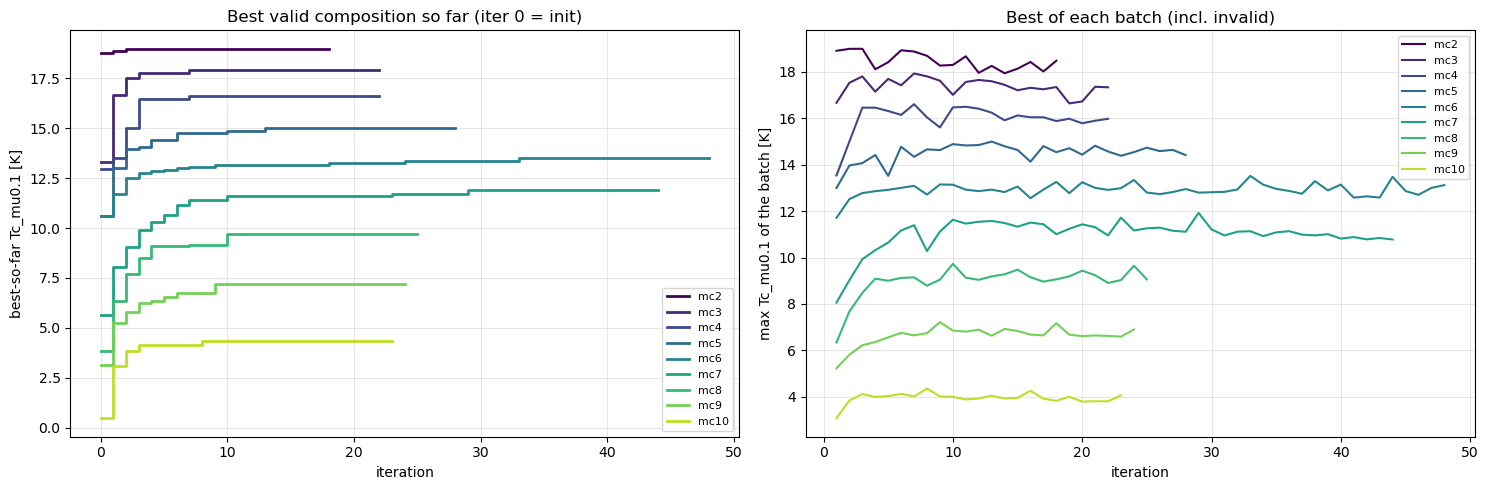

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
cmap = plt.cm.viridis(np.linspace(0, 0.9, len(runs)))
for r, c in zip(runs, cmap):
    d = r['df']; v = d[d.valid]
    its = np.arange(0, r['n_iter'] + 1)
    ax[0].step(its, [v[v.iteration <= i].Tc.max() for i in its], where='post', color=c, lw=2, label=r['label'])
    io = d[d.iteration > 0]
    ax[1].plot(io.groupby('iteration').Tc.max(), color=c, lw=1.5, label=r['label'])
ax[0].set(xlabel='iteration', ylabel=f'best-so-far {TARGET} [K]', title='Best valid composition so far (iter 0 = init)')
ax[1].set(xlabel='iteration', ylabel=f'max {TARGET} of the batch [K]', title='Best of each batch (incl. invalid)')
for a in ax:
    a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

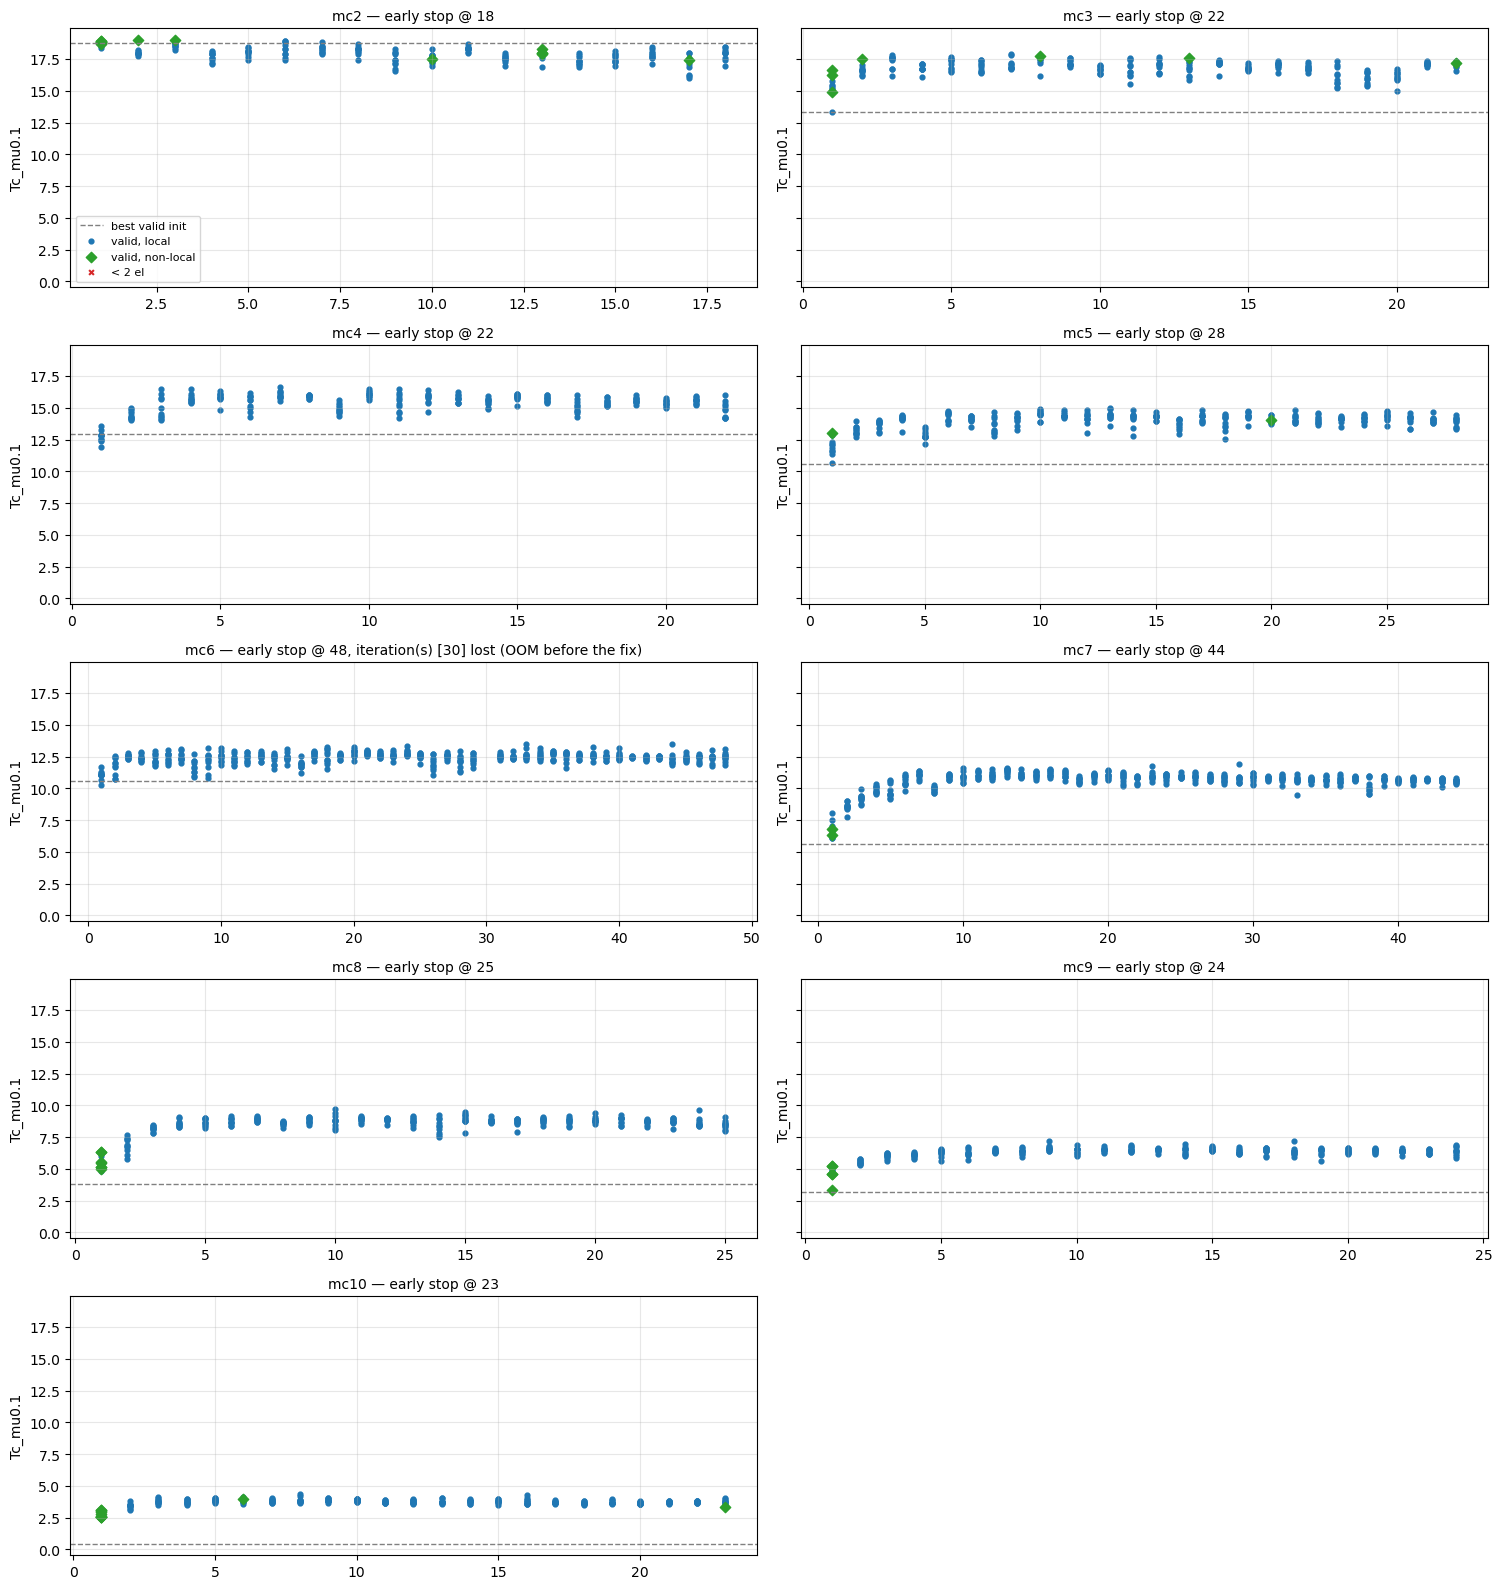

In [5]:
def scatter_runs(rs, title_key='label'):
    n = len(rs)
    fig, axes = plt.subplots((n + 1) // 2, 2, figsize=(15, 3.2 * ((n + 1) // 2)), sharey=True, squeeze=False)
    for a, r in zip(axes.flat, rs):
        d = r['df']; io = d[d.iteration > 0]
        a.axhline(d[(d.iteration == 0) & d.valid].Tc.max(), color='gray', ls='--', lw=1, label='best valid init')
        loc = io.source == 'local'
        a.scatter(io[io.valid & loc].iteration, io[io.valid & loc].Tc, s=12, c='C0', label='valid, local')
        a.scatter(io[io.valid & ~loc].iteration, io[io.valid & ~loc].Tc, s=28, c='C2', marker='D', label='valid, non-local')
        a.scatter(io[~io.valid].iteration, io[~io.valid].Tc, s=12, c='C3', marker='x', label=f"< {r['mc']} el")
        a.set_title(f"{r[title_key]} — {r['status']}", fontsize=10); a.grid(alpha=.3); a.set_ylabel(TARGET)
    axes.flat[0].legend(fontsize=8)
    for a in list(axes.flat)[n:]:
        a.axis('off')
    plt.tight_layout(); plt.show()

scatter_runs(runs)

## 3. Composition of the evaluated batches — mean element fraction per iteration

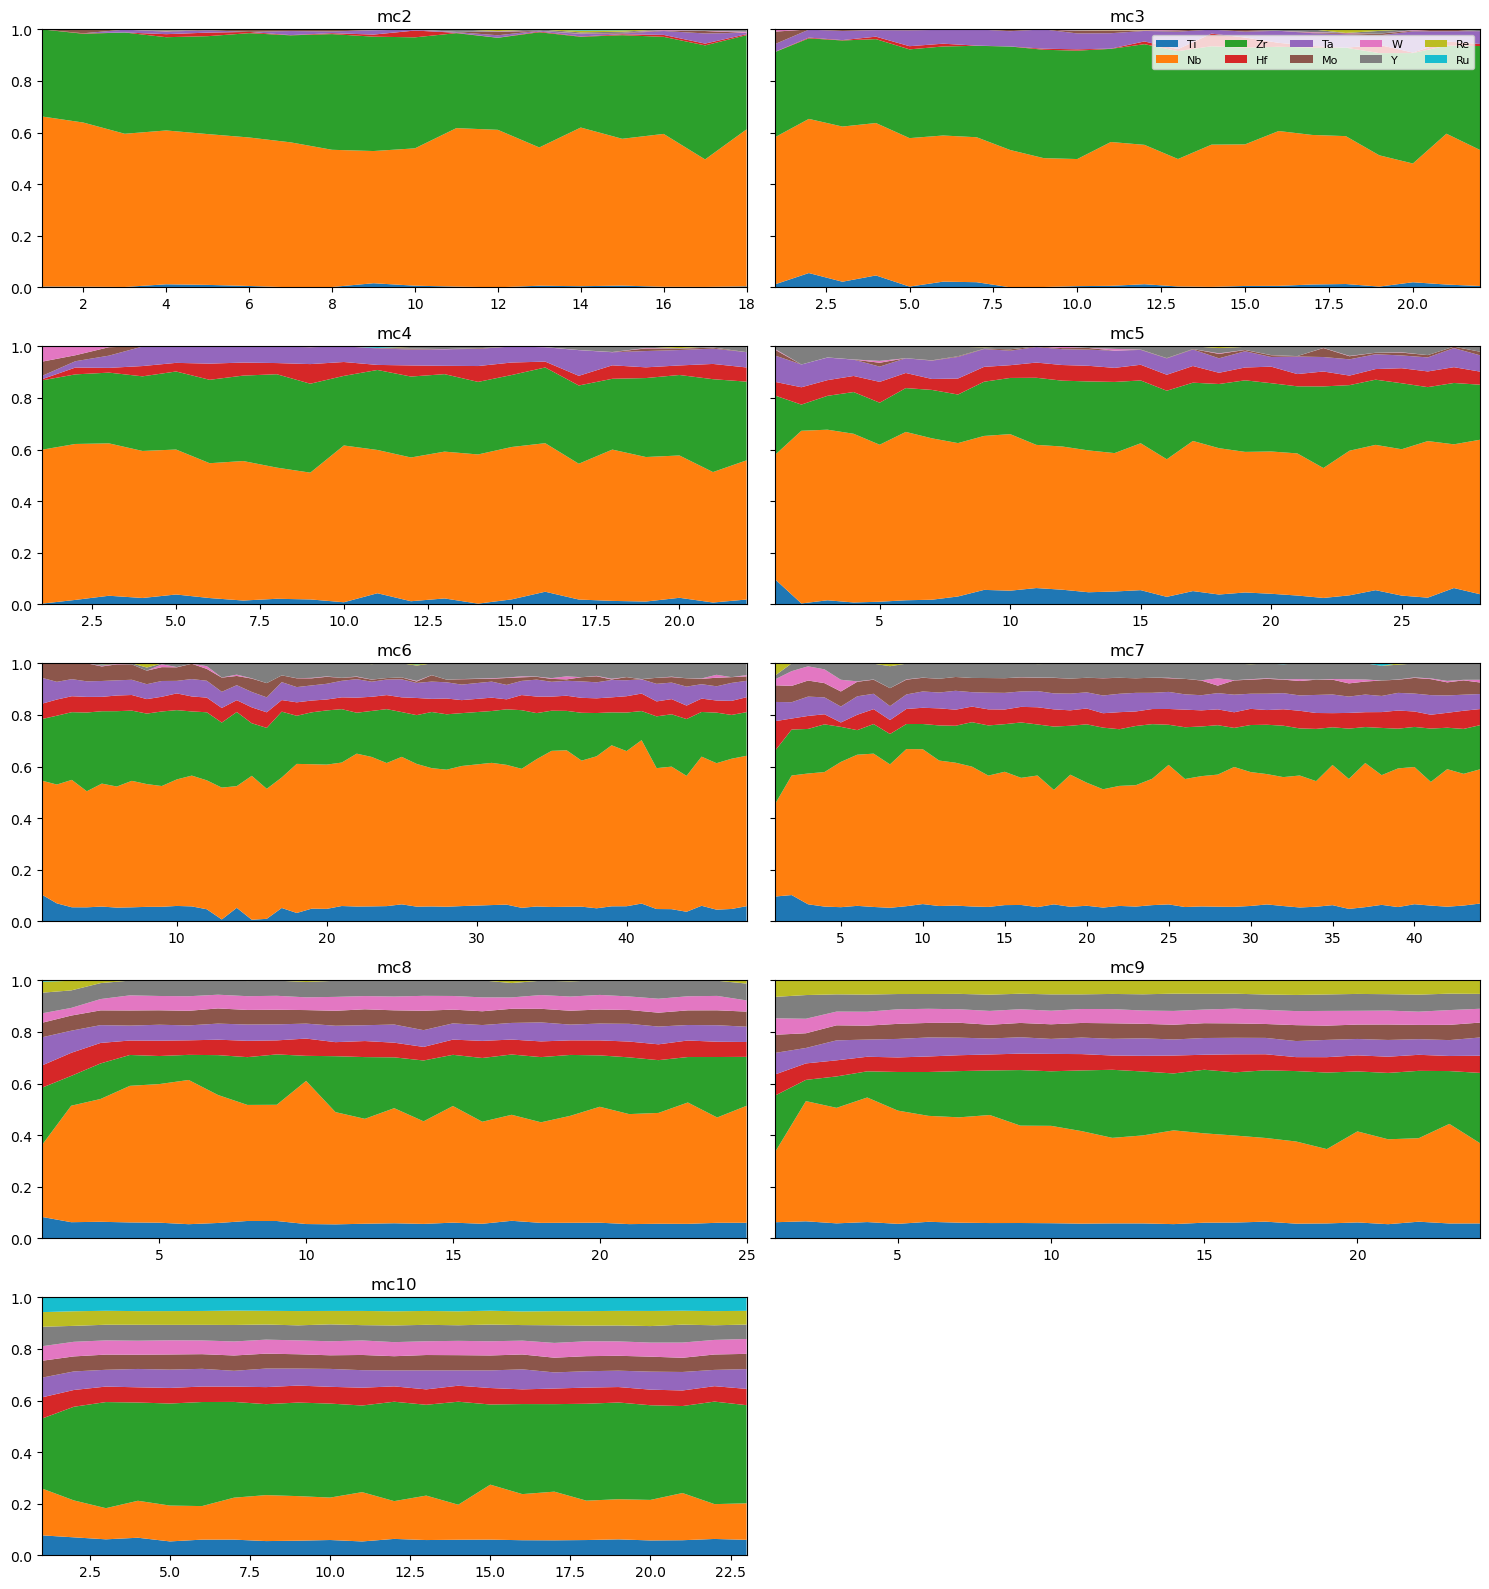

In [6]:
def stack_runs(rs):
    n = len(rs)
    fig, axes = plt.subplots((n + 1) // 2, 2, figsize=(15, 3.2 * ((n + 1) // 2)), sharey=True, squeeze=False)
    for a, r in zip(axes.flat, rs):
        io = r['df'][r['df'].iteration > 0]
        m = io.groupby('iteration')[ELEMENTS].mean()
        a.stackplot(m.index, m.T.values, labels=ELEMENTS, colors=[EL_COLORS[e] for e in ELEMENTS])
        a.set(xlim=(m.index.min(), m.index.max()), ylim=(0, 1), title=r['label'])
    axes.flat[min(1, n - 1)].legend(ncol=5, fontsize=8, loc='upper right')
    for a in list(axes.flat)[n:]:
        a.axis('off')
    plt.tight_layout(); plt.show()

stack_runs(runs)

## 4. Champions — top-5 valid compositions per run

mincomp,iteration,source,Tc,lam,theta,VEC,n_comp,comp
2,3,local,18.99,1.14,273,4.59,2,Nb59 Zr41
2,2,face,18.98,1.14,273,4.61,2,Nb61 Zr39
2,3,face,18.98,1.14,273,4.60,2,Nb60 Zr40
2,2,local,18.97,1.14,273,4.61,2,Nb61 Zr39
2,6,local,18.92,1.14,273,4.57,2,Nb57 Zr43
3,7,local,17.92,1.10,271,4.61,3,Nb56 Zr39 Ta5
3,8,local,17.80,1.09,271,4.57,3,Nb52 Zr43 Ta5
3,3,local,17.80,1.09,271,4.65,3,Nb59 Zr35 Ta5
3,7,local,17.79,1.09,271,4.61,3,Nb55 Zr39 Ta6
3,8,local,17.78,1.09,271,4.58,3,Nb52 Zr42 Ta6


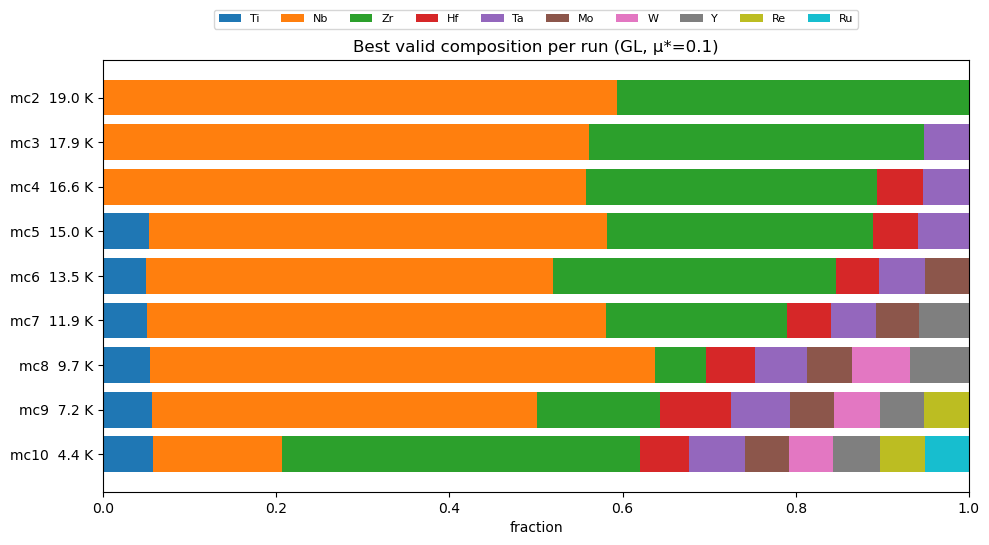

In [7]:
def champ_bar(champ, labels, title):
    fig, ax = plt.subplots(figsize=(10, 0.45 * len(champ) + 1.5))
    left = np.zeros(len(champ))
    for el in ELEMENTS:
        ax.barh(labels, champ[el], left=left, color=EL_COLORS[el], label=el)
        left += champ[el].values
    ax.set(xlabel='fraction', title=title); ax.invert_yaxis()
    ax.legend(ncol=10, fontsize=8, loc='lower center', bbox_to_anchor=(.5, 1.06))
    plt.tight_layout(); plt.show()

top = (ALL[ALL.valid].sort_values('Tc', ascending=False)
       .groupby('mincomp').head(5).sort_values(['mincomp', 'Tc'], ascending=[True, False]))
display(top[['mincomp', 'iteration', 'source', 'Tc', 'lam', 'theta', 'VEC', 'n_comp', 'comp']]
        .style.format({'Tc': '{:.2f}', 'lam': '{:.2f}', 'theta': '{:.0f}', 'VEC': '{:.2f}'}, na_rep='—').hide(axis='index'))
champ = ALL[ALL.valid].loc[lambda x: x.groupby('mincomp').Tc.idxmax()].set_index('mincomp')
champ_bar(champ, [f'mc{i}  {t:.1f} K' for i, t in zip(champ.index, champ.Tc)], 'Best valid composition per run (GL, μ*=0.1)')

## 5. Pareto front: best Tc vs. number of elements

All evaluated compositions of the mincomp series pooled (same pipeline/target), counting elements with fraction > 0.05.

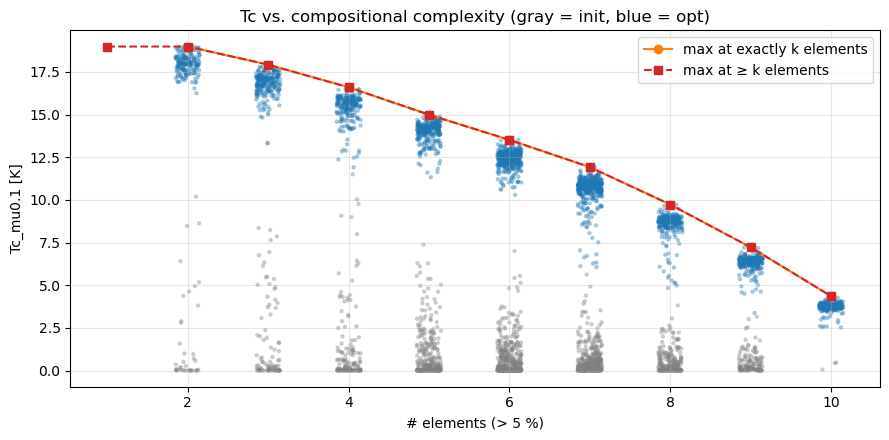

,1,2,3,4,5,6,7,8,9,10
best Tc at ≥ k elements,18.99,18.99,17.92,16.6,14.99,13.52,11.92,9.73,7.22,4.36


In [8]:
U = ALL.drop_duplicates(subset=ELEMENTS)
front = U.groupby('n_comp').Tc.max()
front_ge = pd.Series({k: U[U.n_comp >= k].Tc.max() for k in range(1, 11)})
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(U.n_comp + np.random.default_rng(0).uniform(-.15, .15, len(U)), U.Tc, s=5, alpha=.3,
           c=np.where(U.iteration > 0, 'C0', 'gray'))
ax.plot(front.index, front.values, 'o-', c='C1', label='max at exactly k elements')
ax.plot(front_ge.index, front_ge.values, 's--', c='C3', label='max at ≥ k elements')
ax.set(xlabel='# elements (> 5 %)', ylabel=f'{TARGET} [K]', title='Tc vs. compositional complexity (gray = init, blue = opt)')
ax.grid(alpha=.3); ax.legend(); plt.tight_layout(); plt.show()
front_ge.rename('best Tc at ≥ k elements').to_frame().T.round(2)

## 6. Physics of the champions: λ vs θ_D, λ vs VEC

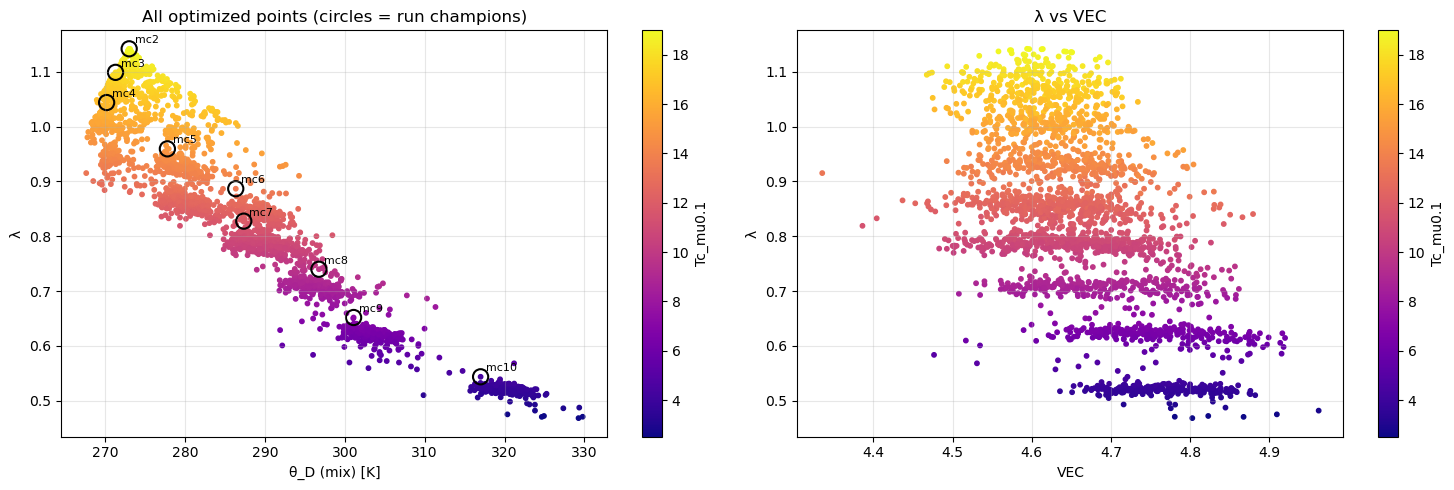

corr(λ, Tc) = 0.998,  corr(θ_D, Tc) = -0.937


In [9]:
O = ALL[ALL.iteration > 0]
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sc = ax[0].scatter(O.theta, O.lam, c=O.Tc, s=10, cmap='plasma')
ax[0].scatter(champ.theta, champ.lam, s=120, facecolor='none', edgecolor='k', lw=1.5)
for mc, row in champ.iterrows():
    ax[0].annotate(f'mc{mc}', (row.theta, row.lam), fontsize=8, xytext=(4, 4), textcoords='offset points')
plt.colorbar(sc, ax=ax[0], label=TARGET)
ax[0].set(xlabel='θ_D (mix) [K]', ylabel='λ', title='All optimized points (circles = run champions)')
sc = ax[1].scatter(O.VEC, O.lam, c=O.Tc, s=10, cmap='plasma')
plt.colorbar(sc, ax=ax[1], label=TARGET)
ax[1].set(xlabel='VEC', ylabel='λ', title='λ vs VEC')
for a in ax:
    a.grid(alpha=.3)
plt.tight_layout(); plt.show()
print(f"corr(λ, Tc) = {O[['lam', 'Tc']].corr().iloc[0, 1]:.3f},  corr(θ_D, Tc) = {O[['theta', 'Tc']].corr().iloc[0, 1]:.3f}")

## 7. Surrogate quality — CatBoost prediction (at selection) vs KKR result

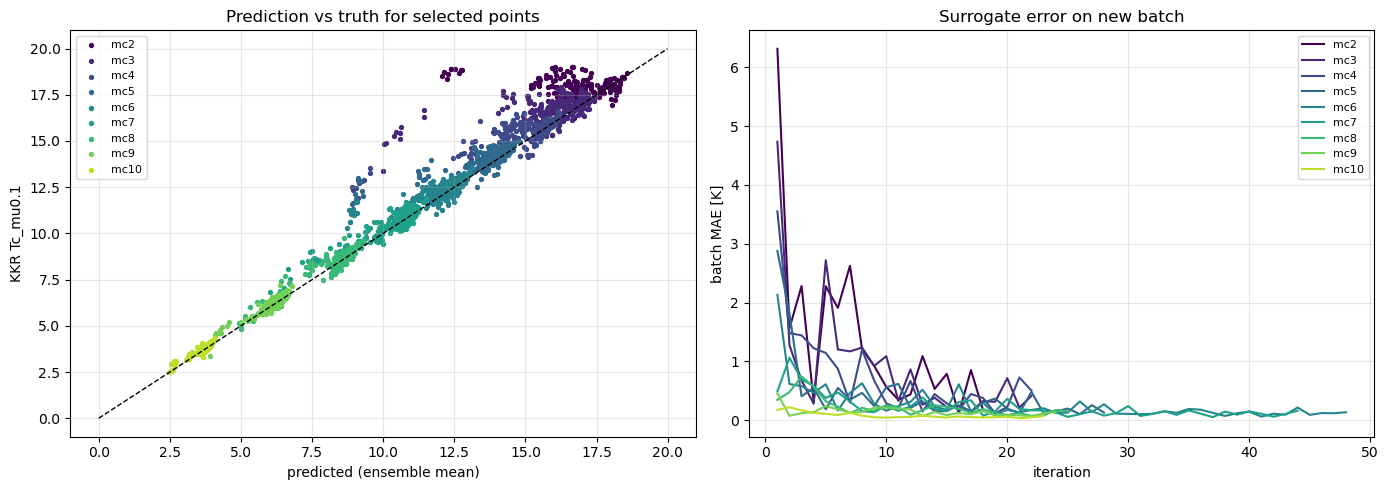

,n,MAE,bias,mean_std,within_1sigma,within_2sigma
label,,,,,,
mc2,180,1.352777,1.262208,1.505345,75%,100%
mc3,220,0.898723,0.799660,0.975975,69%,97%
mc4,220,0.750975,0.618503,0.734186,52%,97%
mc5,280,0.440106,0.364742,0.463370,61%,92%
mc6,470,0.273693,0.150605,0.310049,62%,91%
mc7,440,0.226284,0.102234,0.253719,59%,88%
mc8,250,0.230474,0.151976,0.260535,62%,89%
mc9,240,0.148978,0.083008,0.174994,60%,88%
mc10,230,0.084317,0.044675,0.096199,66%,93%


In [10]:
def surrogate(rs, key='label'):
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    out = []
    cm = plt.cm.viridis(np.linspace(0, 0.9, len(rs)))
    for r, c in zip(rs, cm):
        io = r['df'][(r['df'].iteration > 0) & r['df'].pred.notna()]
        err = io.Tc - io.pred; z = err / io.pred_std
        ax[0].scatter(io.pred, io.Tc, s=8, color=c, label=r[key])
        out.append({key: r[key], 'n': len(io), 'MAE': err.abs().mean(), 'bias': err.mean(),
                    'mean_std': io.pred_std.mean(), 'within_1sigma': (z.abs() < 1).mean(), 'within_2sigma': (z.abs() < 2).mean()})
        ax[1].plot(io.assign(ae=err.abs()).groupby('iteration').ae.mean(), color=c, label=r[key])
    lim = [0, max(r['df'].Tc.max() for r in rs) + 1]
    ax[0].plot(lim, lim, 'k--', lw=1)
    ax[0].set(xlabel='predicted (ensemble mean)', ylabel=f'KKR {TARGET}', title='Prediction vs truth for selected points')
    ax[1].set(xlabel='iteration', ylabel='batch MAE [K]', title='Surrogate error on new batch')
    for a in ax:
        a.grid(alpha=.3); a.legend(fontsize=8)
    plt.tight_layout(); plt.show()
    return (pd.DataFrame(out).set_index(key).style.format('{:.2f}')
            .format({'n': '{:d}', 'within_1sigma': '{:.0%}', 'within_2sigma': '{:.0%}'}))

surrogate(runs)

## 8. Where did the selected points come from? (acquisition source)

In [11]:
src = ALL[ALL.iteration > 0].groupby(['mincomp', 'source']).size().unstack(fill_value=0)
src.assign(champion_source=ALL[ALL.valid & (ALL.iteration > 0)].loc[lambda x: x.groupby('mincomp').Tc.idxmax()]
           .set_index('mincomp').source)

source,face,global,local,champion_source
mincomp,,,,
2,14,0,166,local
3,7,0,213,local
4,0,0,220,local
5,2,0,278,local
6,0,0,470,local
7,2,0,438,local
8,1,6,243,local
9,0,5,235,local
10,0,12,218,local


## 9. Distance travelled from the best init composition

Euclidean distance in composition space between each run's champion and its best valid init point.

In [12]:
def travel(rs):
    out = []
    for r in rs:
        v = r['df'][r['df'].valid]
        b0 = v[v.iteration == 0].loc[lambda x: x.Tc.idxmax()]
        b = v.loc[v.Tc.idxmax()]
        out.append(dict(run=r['label'], init_best=b0.comp, init_Tc=b0.Tc, champion=b.comp, champ_Tc=b.Tc,
                        distance=float(np.linalg.norm(b[ELEMENTS].values.astype(float) - b0[ELEMENTS].values.astype(float)))))
    return pd.DataFrame(out).set_index('run').round(3)

travel(runs)

,init_best,init_Tc,champion,champ_Tc,distance
run,,,,,
mc2,Nb67 Zr33,18.779,Nb59 Zr41,18.987,0.105
mc3,Zr66 Nb19 Ta15,13.298,Nb56 Zr39 Ta5,17.924,0.467
mc4,Nb59 Zr28 Mo7 W6,12.962,Nb56 Zr34 Hf5 Ta5,16.600,0.133
mc5,Nb43 Zr23 Ti13 Ta11 Mo5 Hf5,10.602,Nb53 Zr31 Ta6 Ti5 Hf5,14.993,0.166
mc6,Nb43 Zr23 Ti13 Ta11 Mo5 Hf5,10.602,Nb47 Zr33 Ta5 Hf5 Mo5 Ti5,13.515,0.145
mc7,Zr26 Nb26 Hf16 Re8 Ti8 Mo8 Ta7,5.623,Nb53 Zr21 Y6 Ta5 Hf5 Ti5 Mo5,11.921,0.321
mc8,Zr31 Nb15 Mo15 Y11 Re9 Hf7 Ti7 Ta5 Ru1,3.812,Nb58 Y7 W7 Ta6 Zr6 Hf6 Ti5 Mo5,9.726,0.525
mc9,Zr24 Nb20 Mo11 Re10 Hf9 W7 Ta7 Y6 Ti6,3.148,Nb45 Zr14 Hf8 Ta7 Ti6 W5 Re5 Y5 Mo5,7.218,0.275
mc10,Ti15 Nb14 Mo14 W13 Y9 Zr9 Ru7 Ta6 Hf6 Re6,0.465,Zr41 Nb15 Ta6 Ti6 Hf6 Y5 Re5 Ru5 W5 Mo5,4.356,0.362


## 10. Interior init (`.gl.interior.csv`, no face/edge points) vs full init — mincomp 2 and 3

Question: does the optimizer find the binary/ternary optimum when the init set contains no points on the faces/edges
of the simplex, i.e. when it has to *walk* there?

,iters,status,n_init_valid,init_best,opt_best,gain_K,best_iter,frac_new_valid,champion,n_el,lam,theta,VEC
label,,,,,,,,,,,,,
mc2,18,early stop @ 18,1707,18.78,18.99,+0.21,3,100%,Nb59 Zr41,2,1.14,273,4.59
mc3,22,early stop @ 22,1668,13.30,17.92,+4.63,7,100%,Nb56 Zr39 Ta5,3,1.10,271,4.61
mc2 int,32,early stop @ 32,997,11.50,18.98,+7.48,17,100%,Nb62 Zr38,2,1.14,273,4.62
mc3 int,37,early stop @ 37,997,11.50,17.79,+6.30,22,100%,Nb57 Zr37 Ta6,3,1.09,271,4.63


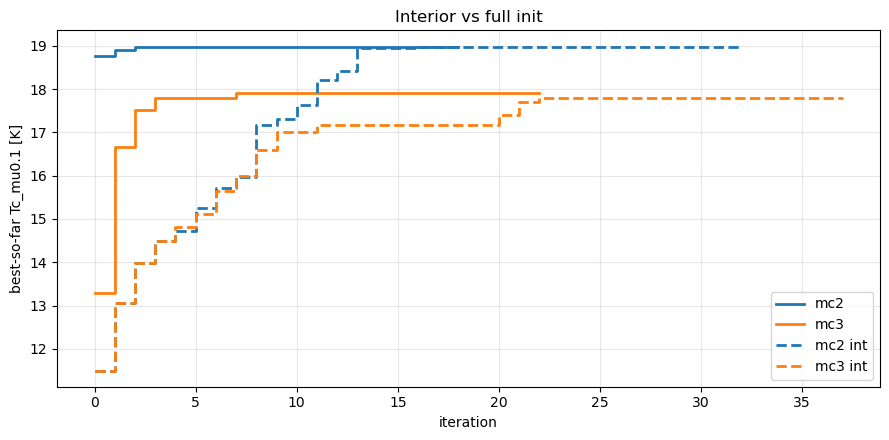

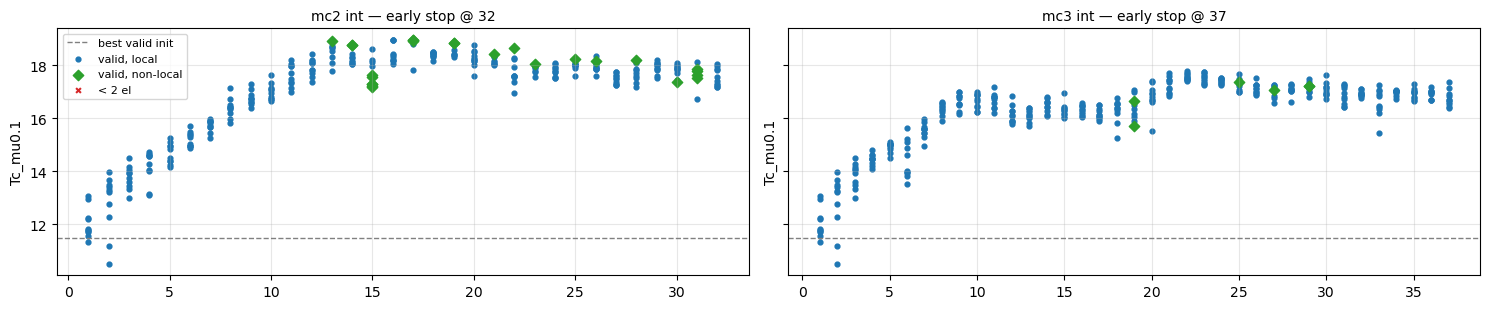

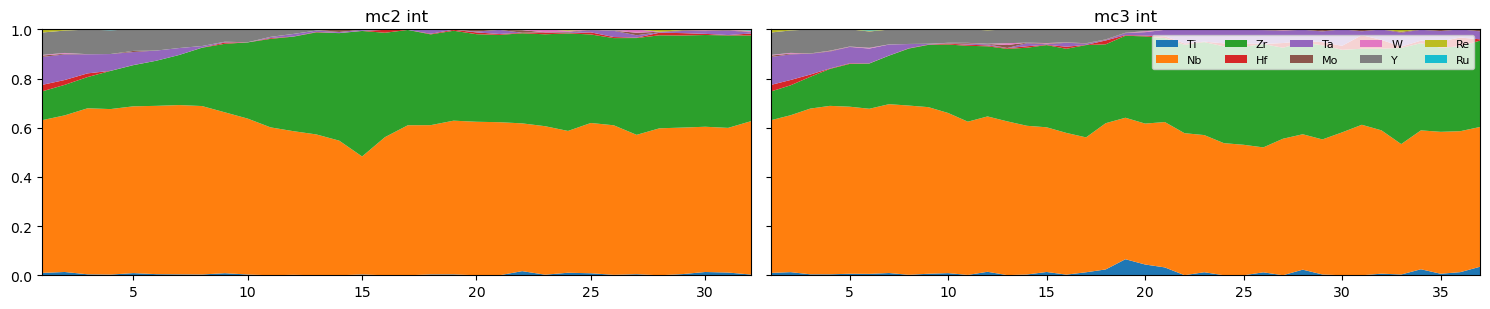

,init_best,init_Tc,champion,champ_Tc,distance
run,,,,,
mc2,Nb67 Zr33,18.779,Nb59 Zr41,18.987,0.105
mc3,Zr66 Nb19 Ta15,13.298,Nb56 Zr39 Ta5,17.924,0.467
mc2 int,Nb61 Ta12 Zr11 Y9 Hf4 W1 Re1,11.497,Nb62 Zr38,18.980,0.318
mc3 int,Nb61 Ta12 Zr11 Y9 Hf4 W1 Re1,11.497,Nb57 Zr37 Ta6,17.794,0.297


In [13]:
pairs = [r for r in runs_all if r['mc'] in (2, 3) and r['beta'] == 2]
s_int = summary(pairs, key='label')
display(s_int.style.format(FMT, na_rep='—'))
fig, ax = plt.subplots(figsize=(9, 4.5))
for r in pairs:
    v = r['df'][r['df'].valid]
    its = np.arange(0, r['n_iter'] + 1)
    ax.step(its, [v[v.iteration <= i].Tc.max() for i in its], where='post', lw=2,
            ls='--' if r['interior'] else '-', color='C0' if r['mc'] == 2 else 'C1', label=r['label'])
ax.set(xlabel='iteration', ylabel=f'best-so-far {TARGET} [K]', title='Interior vs full init')
ax.grid(alpha=.3); ax.legend(); plt.tight_layout(); plt.show()
scatter_runs(runs_int)
stack_runs(runs_int)
travel(pairs)

## 11. Acquisition β scan at `min_components = 7`

Same init set and settings, only the UCB weight β differs: β = 0 (pure exploitation), 1, 2, 5, 10.

,iters,status,n_init_valid,init_best,opt_best,gain_K,best_iter,frac_new_valid,champion,n_el,lam,theta,VEC,face,local
beta,,,,,,,,,,,,,,,
0.000000,30,"early stop @ 31, iteration(s) [30] lost (OOM before the fix)",738,5.62,11.98,+6.36,15,100%,Nb52 Zr22 Ta6 Hf5 Mo5 Ti5 Y5,7,0.83,287,4.63,1,299
1.000000,40,"early stop @ 41, iteration(s) [30] lost (OOM before the fix)",738,5.62,11.88,+6.25,26,100%,Nb51 Zr22 Hf6 Ta5 Ti5 Y5 Mo5,7,0.83,287,4.62,1,399
2.000000,44,early stop @ 44,738,5.62,11.92,+6.30,29,100%,Nb53 Zr21 Y6 Ta5 Hf5 Ti5 Mo5,7,0.83,287,4.62,2,438
5.000000,22,early stop @ 22,738,5.62,11.79,+6.17,7,100%,Nb59 Zr15 Ti6 Ta5 Hf5 Y5 Mo5,7,0.82,289,4.69,2,218
10.000000,54,"early stop @ 55, iteration(s) [30] lost (OOM before the fix)",738,5.62,11.98,+6.36,40,100%,Nb50 Zr24 Ta5 Ti5 Mo5 Hf5 Y5,7,0.83,288,4.61,4,536


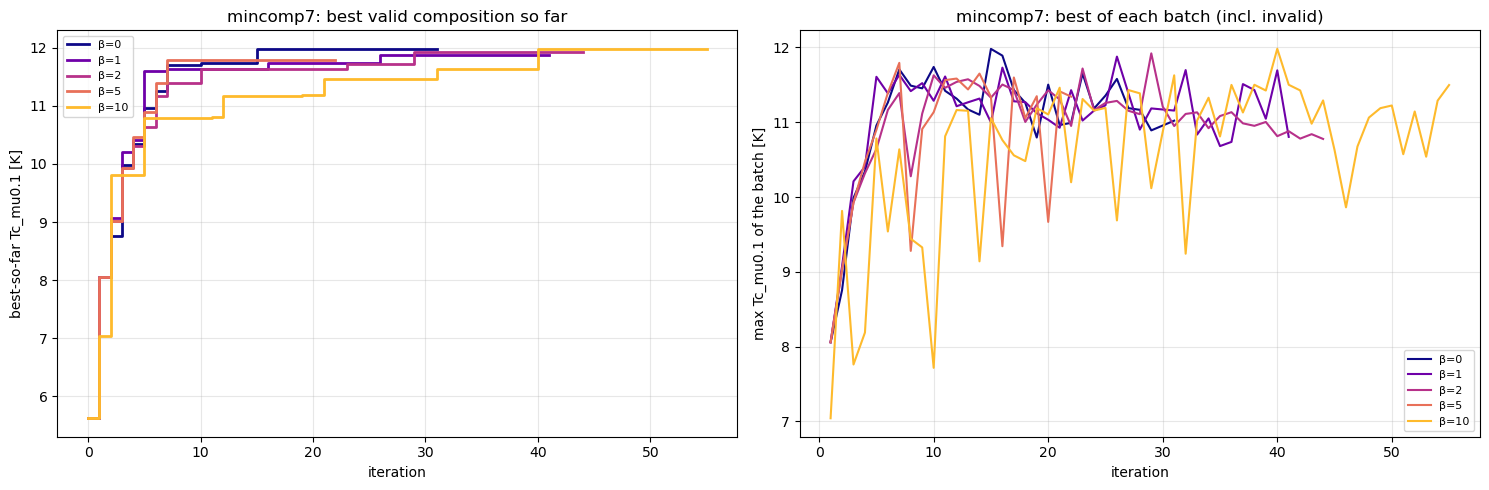

In [14]:
summ_b = summary(runs_beta, key='beta')
src_b = ALLB[ALLB.iteration > 0].groupby(['acqbeta', 'source']).size().unstack(fill_value=0)
summ_b = summ_b.join(src_b)
display(summ_b.style.format(FMT, na_rep='—'))
cmap_b = plt.cm.plasma(np.linspace(0, 0.85, len(runs_beta)))
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for r, c in zip(runs_beta, cmap_b):
    d = r['df']; v = d[d.valid]
    its = np.arange(0, r['n_iter'] + 1)
    ax[0].step(its, [v[v.iteration <= i].Tc.max() for i in its], where='post', color=c, lw=2, label=f"β={r['beta']:g}")
    ax[1].plot(d[d.iteration > 0].groupby('iteration').Tc.max(), color=c, lw=1.5, label=f"β={r['beta']:g}")
ax[0].set(xlabel='iteration', ylabel=f'best-so-far {TARGET} [K]', title='mincomp7: best valid composition so far')
ax[1].set(xlabel='iteration', ylabel=f'max {TARGET} of the batch [K]', title='mincomp7: best of each batch (incl. invalid)')
for a in ax:
    a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

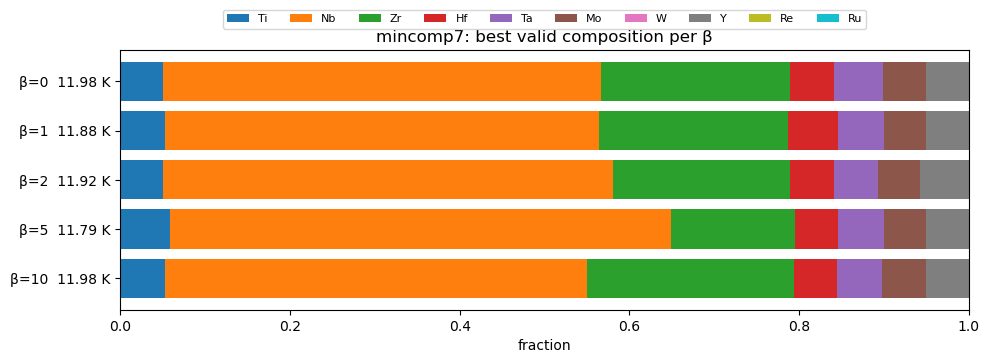

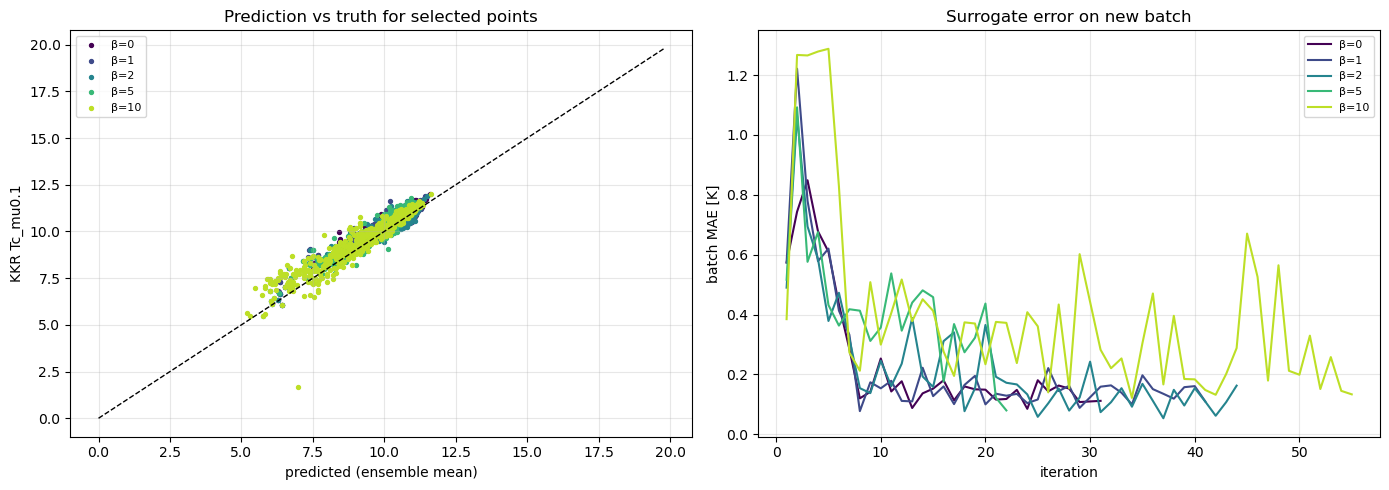

,n,MAE,bias,mean_std,within_1sigma,within_2sigma
beta_label,,,,,,
β=0,300,0.248963,0.107575,0.181184,44%,69%
β=1,400,0.230701,0.071645,0.182517,45%,74%
β=2,440,0.226284,0.102234,0.253719,59%,88%
β=5,220,0.418128,0.327240,0.496235,62%,89%
β=10,540,0.389418,0.278473,0.420673,61%,93%


In [15]:
champ_b = ALLB[ALLB.valid].loc[lambda x: x.groupby('acqbeta').Tc.idxmax()].set_index('acqbeta')
champ_bar(champ_b, [f'β={b:g}  {t:.2f} K' for b, t in zip(champ_b.index, champ_b.Tc)], 'mincomp7: best valid composition per β')
for r in runs_beta:
    r['beta_label'] = f"β={r['beta']:g}"
surrogate(runs_beta, key='beta_label')

## 12. Comparison with the previous optimization (A-mode η, site-DOS normalisation, μ* = 0.2, max 0.75)

Old runs: `opt.ratios.mix/*slim.mu0.2.acqbeta2*mincomp{2..8}*` (no G-mode, no Lloyd). Absolute Tc are **not** directly
comparable (different μ*, different η normalisation; both μ* values were the respective calibrations against
the literature baseline), so we compare (a) champion compositions, (b) the shape of the Tc-vs-#elements curve
normalised to the binary optimum, (c) λ and θ_D of the champions, (d) which elements fill the forced slots.

In [16]:
runs_old = sorted((load_run(d, TARGET_OLD) for d in BASE_OLD.glob('*slim.mu0.2.acqbeta2.*mincomp*') if d.is_dir()),
                  key=lambda r: r['mc'])
ALL_OLD = pd.concat([r['df'] for r in runs_old], ignore_index=True)
champ_old = ALL_OLD[ALL_OLD.valid].loc[lambda x: x.groupby('mincomp').Tc.idxmax()].set_index('mincomp')

cmp = pd.DataFrame({
    'Tc_new (GL μ0.1)': champ.Tc, 'Tc_old (A μ0.2)': champ_old.Tc,
    'λ_new': champ.lam, 'λ_old': champ_old.lam, 'θ_new': champ.theta, 'θ_old': champ_old.theta,
    'VEC_new': champ.VEC, 'VEC_old': champ_old.VEC,
    'champion_new': champ.comp, 'champion_old': champ_old.comp})
cmp['Tc_new/Tc_new(mc2)'] = cmp['Tc_new (GL μ0.1)'] / cmp['Tc_new (GL μ0.1)'].iloc[0]
cmp['Tc_old/Tc_old(mc2)'] = cmp['Tc_old (A μ0.2)'] / cmp['Tc_old (A μ0.2)'].iloc[0]
cmp['dist_new_old'] = [float(np.linalg.norm(champ.loc[m, ELEMENTS].values.astype(float) - champ_old.loc[m, ELEMENTS].values.astype(float)))
                       if m in champ_old.index else np.nan for m in cmp.index]
cmp.style.format({c: '{:.2f}' for c in cmp.columns if cmp[c].dtype != object}, na_rep='—').format(
    {'θ_new': '{:.0f}', 'θ_old': '{:.0f}'}, na_rep='—')

,Tc_new (GL μ0.1),Tc_old (A μ0.2),λ_new,λ_old,θ_new,θ_old,VEC_new,VEC_old,champion_new,champion_old,Tc_new/Tc_new(mc2),Tc_old/Tc_old(mc2),dist_new_old
mincomp,,,,,,,,,,,,,
2,18.986597,18.958667,1.141722,1.544255,273,273,4.594152,4.584749,Nb59 Zr41,Nb58 Zr42,1.000000,1.000000,0.013297
3,17.923905,18.139057,1.098764,1.464020,271,281,4.612566,4.594712,Nb56 Zr39 Ta5,Nb59 Zr35 Ti5,0.944029,0.956769,0.086326
4,16.599910,16.898695,1.043739,1.397486,270,280,4.610685,4.590284,Nb56 Zr34 Hf5 Ta5,Nb54 Zr35 Ti6 Ta5,0.874296,0.891344,0.081457
5,14.992523,15.690199,0.959310,1.336355,278,278,4.588359,4.621643,Nb53 Zr31 Ta6 Ti5 Hf5,Nb57 Zr28 Ta5 Ti5 Hf5,0.789637,0.827600,0.050072
6,13.515111,14.061769,0.886608,1.250518,286,278,4.622881,4.589899,Nb47 Zr33 Ta5 Hf5 Mo5 Ti5,Nb59 Zr21 Ta5 Hf5 Ti5 Y5,0.711824,0.741707,0.181496
7,11.920640,12.057615,0.827472,1.132282,287,288,4.624592,4.606100,Nb53 Zr21 Y6 Ta5 Hf5 Ti5 Mo5,Nb50 Zr23 Y6 Ta6 Mo5 Ti5 Hf5,0.627845,0.635995,0.036672
8,9.726358,9.663034,0.739798,1.014760,297,293,4.813309,4.542834,Nb58 Y7 W7 Ta6 Zr6 Hf6 Ti5 Mo5,Zr35 Nb34 Hf6 Ti5 Ta5 W5 Mo5 Y5,0.512275,0.509690,0.378742
9,7.217876,—,0.651787,—,301,—,4.824162,—,Nb45 Zr14 Hf8 Ta7 Ti6 W5 Re5 Y5 Mo5,—,0.380156,—,—
10,4.356200,—,0.543711,—,317,—,4.720952,—,Zr41 Nb15 Ta6 Ti6 Hf6 Y5 Re5 Ru5 W5 Mo5,—,0.229436,—,—


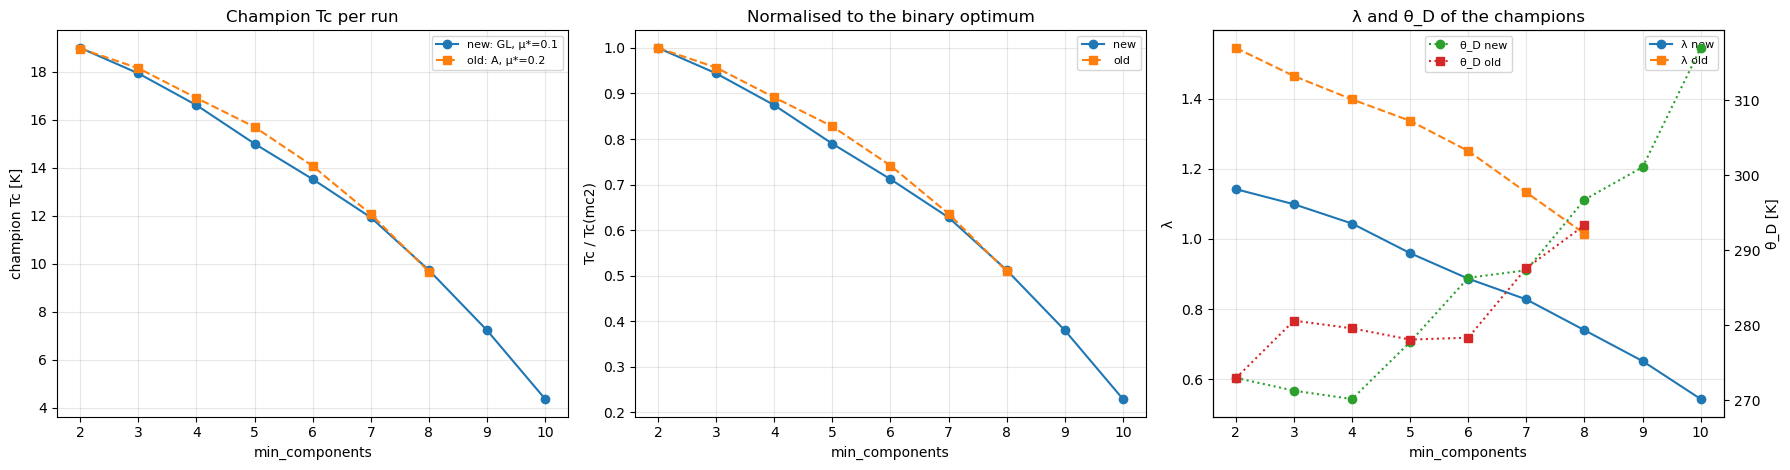

/tmp/ipykernel_247318/3688214685.py:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  both = pd.concat([champ.assign(set='new'), champ_old.assign(set='old')]).reset_index()


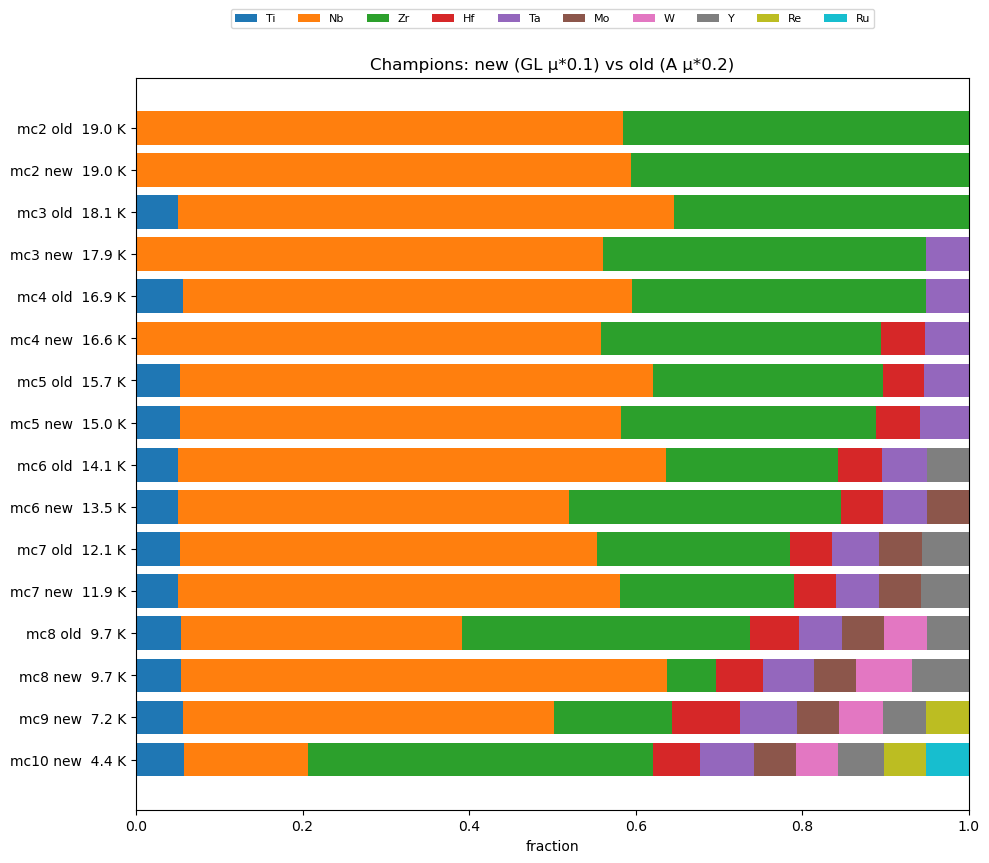

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
ax[0].plot(champ.index, champ.Tc, 'o-', label='new: GL, μ*=0.1')
ax[0].plot(champ_old.index, champ_old.Tc, 's--', label='old: A, μ*=0.2')
ax[0].set(xlabel='min_components', ylabel='champion Tc [K]', title='Champion Tc per run')
ax[1].plot(champ.index, champ.Tc / champ.Tc.iloc[0], 'o-', label='new')
ax[1].plot(champ_old.index, champ_old.Tc / champ_old.Tc.iloc[0], 's--', label='old')
ax[1].set(xlabel='min_components', ylabel='Tc / Tc(mc2)', title='Normalised to the binary optimum')
ax[2].plot(champ.index, champ.lam, 'o-', label='λ new'); ax[2].plot(champ_old.index, champ_old.lam, 's--', label='λ old')
a2 = ax[2].twinx()
a2.plot(champ.index, champ.theta, 'o:', c='C2', label='θ_D new'); a2.plot(champ_old.index, champ_old.theta, 's:', c='C3', label='θ_D old')
a2.set_ylabel('θ_D [K]'); a2.legend(loc='upper center', fontsize=8)
ax[2].set(xlabel='min_components', ylabel='λ', title='λ and θ_D of the champions')
for a in ax:
    a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

both = pd.concat([champ.assign(set='new'), champ_old.assign(set='old')]).reset_index()
both = both.sort_values(['mincomp', 'set'], ascending=[True, False])
champ_bar(both.reset_index(drop=True), [f"mc{m} {s}  {t:.1f} K" for m, s, t in zip(both.mincomp, both.set, both.Tc)],
          'Champions: new (GL μ*0.1) vs old (A μ*0.2)')

In [18]:
# which elements occupy the forced slots — mean fraction in the champions (mc ≥ 3) and how often > 5 %
sel = lambda c: c.loc[c.index >= 3, ELEMENTS]
occ = pd.DataFrame({'new: mean frac': sel(champ).mean(), 'old: mean frac': sel(champ_old).mean(),
                    'new: # champions >5%': (sel(champ) > RATIO).sum(), 'old: # champions >5%': (sel(champ_old) > RATIO).sum()})
display(occ.T.round(3))

# same KKR composition ranking? Spearman between the two Tc definitions on the old champions' top points is not possible
# without recomputation; instead compare the Nb/Zr ratio of the main basin
for name, c in [('new', champ), ('old', champ_old)]:
    print(name, 'Nb/(Nb+Zr) of champions:', (c.Nb / (c.Nb + c.Zr)).round(2).to_dict())

,Ti,Nb,Zr,Hf,Ta,Mo,W,Y,Re,Ru
new: mean frac,0.040,0.478,0.273,0.050,0.058,0.032,0.021,0.029,0.013,0.006
old: mean frac,0.053,0.521,0.295,0.035,0.044,0.017,0.009,0.026,0.000,0.000
new: # champions >5%,6.000,8.000,8.000,7.000,8.000,5.000,3.000,4.000,2.000,1.000
old: # champions >5%,6.000,6.000,6.000,4.000,5.000,2.000,1.000,3.000,0.000,0.000


new Nb/(Nb+Zr) of champions: {2: 0.59, 3: 0.59, 4: 0.62, 5: 0.63, 6: 0.59, 7: 0.72, 8: 0.91, 9: 0.76, 10: 0.26}
old Nb/(Nb+Zr) of champions: {2: 0.58, 3: 0.63, 4: 0.6, 5: 0.67, 6: 0.74, 7: 0.68, 8: 0.49}


## 13. Thermodynamics of the champions: bcc / fcc / hcp and ΔH

For the champion of each mincomp run (β = 2), `scripts/structure_compare.py` ran on Topola
(`slurm/topola_td_array.sbatch`, list `slurm/compositions/td_champions_gl.csv`, 2026-11-06/09). It uses the same KKR
settings as the lattice stage of the optimisation (sra, PBE, ew 0.6, bzqlty 10, mxl 3, nmag): an EOS for bcc and fcc, plus
hcp at 5 c/a values. Results: `thermodynamic/<run>/<composition>/structure_summary.json`; pure elements:
`thermodynamic/elements.sra.ew0.6.topola/`.

- **E_fcc − E_bcc, E_hcp − E_bcc** [meV/atom]: > 0 means bcc is lower in energy.
- **ΔH_bcc** = E_bcc(alloy) − Σ c_i E_bcc(i), referenced to bcc elements. The references are `ebulk` from `src/elements.py`
  (ew 0.6), except W and Re (column `ew`, see below). The concentrations c_i are those of the KKR input (6 decimals,
  normalised by AkaiKKR), not the unrounded composition: total energies are ~1e4 Ry, so a 5e-7 difference in c_i
  between a heavy (Re, W, Hf, Ta) and a light (Ti, Y, Zr) element changes ΔH by up to ~200 meV.
- **ΔH_gs** = min over structures E(alloy) − Σ c_i E_gs(i), referenced to the KKR ground state of each element (hcp for Ti, Zr, Hf, Y, Ru).
- **W and Re:** at ew 0.6 the bottom of their valence band lies below the energy contour (Re: B_bcc ≈ 19 000 GPa and bcc
  ground state; W: a0 6.26 instead of 6.01 bohr, energy 0.6–0.8 eV too high). Their references come from the ew 1.0 scans
  `thermodynamic.ew1.0/elements.sra.topola/`. Converged energies do not depend on the window (Ti, Nb, Zr, Ta, Mo, Y within
  1–5 meV between ew 0.6 and 1.0; champions mc9/mc10 within 0.1 mRy between ew 0.6 and 0.7), so the alloys stay at ew 0.6.
  Same choice as Table I of the paper (`PAPER/figures/common.py`).

In [19]:
import sys
sys.path.insert(0, '../scripts')
from src.elements import ELEMENTS as ELEMENT_DATA

TD_LIST = Path('../slurm/compositions/td_champions_gl.csv')
EL_TD = Path('../thermodynamic/elements.sra.ew0.6.topola')
RY_MEV = 13.605693122994 * 1000
STRUCT = ('bcc', 'fcc', 'hcp')
Z_TO_EL = {22: 'Ti', 41: 'Nb', 40: 'Zr', 72: 'Hf', 73: 'Ta', 42: 'Mo', 74: 'W', 39: 'Y', 75: 'Re', 44: 'Ru', 23: 'V', 21: 'Sc'}
EL_TD_WIDE = Path('../thermodynamic.ew1.0/elements.sra.topola')
REF_WIDE_EW = {'W', 'Re'}    # pure W and Re are not converged at ew 0.6 (valence band below the contour) -> ew 1.0 scans


def kkr_input_composition(inp):
    # concentrations exactly as AkaiKKR used them: the rounded values of the .inp, normalised as in specx.f.  Total
    # energies are ~1e4 Ry, so ΔH must use these and not the unrounded composition (5e-7 × 3e4 Ry ≈ 200 meV).
    comp, block = {}, False
    for line in Path(inp).read_text().splitlines():
        if 'anclr' in line and line.lstrip().startswith('c'):
            block = True
            continue
        if block:
            if line.lstrip().startswith('c'):
                break
            f = line.split()
            if len(f) == 2:
                comp[Z_TO_EL[int(round(float(f[0])))]] = float(f[1])
    norm = sum(comp.values())
    return {el: x / norm for el, x in comp.items()}


def read_td(d):
    s = json.loads((d / 'structure_summary.json').read_text())
    t = {f'E_{st}': s[st]['energy_per_atom_ry'] for st in STRUCT}
    a_scan = [float(re.findall(r'_(\d+\.\d+)', f.name)[-1]) for f in (d / 'bcc').glob('*.inp')]
    t.update(most_stable=s['most_stable'], a_bcc=s['bcc']['lattice_constant_bohr'], B_bcc=s['bcc']['bulk_modulus_gpa'],
             dE_fcc=(t['E_fcc'] - t['E_bcc']) * RY_MEV, dE_hcp=(t['E_hcp'] - t['E_bcc']) * RY_MEV,
             comp=kkr_input_composition(sorted((d / 'bcc').glob('*.inp'))[0]))
    t['a_in_scan'] = min(a_scan) < t['a_bcc'] < max(a_scan)
    return t


def element_td(el):
    return read_td((EL_TD_WIDE if el in REF_WIDE_EW else EL_TD) / f'{el}1.0000')


def e_bcc_ref(el):
    return element_td(el)['E_bcc'] if el in REF_WIDE_EW else ELEMENT_DATA[el].ebulk


def element_refs(elements):
    rows = []
    for el in elements:
        t = element_td(el)
        rows.append({'el': el, 'gs_KKR': min(STRUCT, key=lambda st: t[f'E_{st}']),
                     'E_fcc−E_bcc': t['dE_fcc'], 'E_hcp−E_bcc': t['dE_hcp'], 'a_bcc': t['a_bcc'], 'B_bcc': t['B_bcc'],
                     'a in scan': t['a_in_scan'], 'ew': 1.0 if el in REF_WIDE_EW else 0.6, 'E_bcc−ref': (t['E_bcc'] - e_bcc_ref(el)) * RY_MEV,
                     'E_gs−E_bcc': min(0.0, t['dE_fcc'], t['dE_hcp'])})
    return pd.DataFrame(rows).set_index('el')


def champions_td(prefix, champ=None):
    # rows <prefix>_mc<m> of TD_LIST; champ (index mincomp) = the notebook's champions, checked against the TD composition
    lst = pd.read_csv(TD_LIST)
    lst = lst[lst.tag.str.startswith(prefix + '_mc')]
    rows = []
    for _, r in lst.iterrows():
        mc = int(r.tag.rsplit('_mc', 1)[1])
        t = read_td(Path('..') / r.outdir / r.dirname)
        c = {el: x for el, x in t['comp'].items() if x > 0}
        if champ is not None:
            dev = max(abs(c.get(el, 0.0) - champ.loc[mc, el]) for el in ELEMENTS)
            assert dev < 1e-3, f'{r.tag}: TD composition differs from the notebook champion by {dev:.4f}'
        e_ref = sum(x * e_bcc_ref(el) for el, x in c.items())
        e_min = min(t[f'E_{st}'] for st in STRUCT)
        rows.append({'mincomp': mc, 'Tc': r.Tc, 'champion': comp_str(pd.Series(c)), 'most_stable': t['most_stable'],
                     'E_fcc−E_bcc': t['dE_fcc'], 'E_hcp−E_bcc': t['dE_hcp'], 'a_bcc': t['a_bcc'], 'B_bcc': t['B_bcc'],
                     'a in scan': t['a_in_scan'],
                     'ΔH_bcc': (t['E_bcc'] - e_ref) * RY_MEV,
                     'ΔH_gs': (e_min - e_ref) * RY_MEV - sum(x * REF.loc[el, 'E_gs−E_bcc'] for el, x in c.items())})
    return pd.DataFrame(rows).set_index('mincomp').sort_index()


def td_plot(series):
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
    for (name, t), m in zip(series.items(), 'osd^'):
        ax[0].plot(t.index, t['E_fcc−E_bcc'], m + '-', label=f'{name}: fcc')
        ax[0].plot(t.index, t['E_hcp−E_bcc'], m + '--', label=f'{name}: hcp')
        ax[1].plot(t.index, t['ΔH_bcc'], m + '-', label=f'{name}: ΔH_bcc')
        ax[1].plot(t.index, t['ΔH_gs'], m + ':', label=f'{name}: ΔH_gs')
    ax[0].set(xlabel='mincomp', ylabel='E − E_bcc [meV/atom]', title='Structure energy above bcc (champions)')
    ax[1].set(xlabel='mincomp', ylabel='ΔH [meV/atom]', title='Mixing enthalpy of the champions')
    ax[1].axhline(0, c='k', lw=.8)
    for a in ax:
        a.grid(alpha=.3); a.legend(fontsize=8)
    plt.tight_layout(); plt.show()


REF = element_refs(['Ti', 'Nb', 'Zr', 'Hf', 'Ta', 'Mo', 'W', 'Y', 'Re', 'Ru', 'V', 'Sc'])
REF_FMT = {'E_fcc−E_bcc': '{:.1f}', 'E_hcp−E_bcc': '{:.1f}', 'a_bcc': '{:.3f}', 'B_bcc': '{:.0f}', 'ew': '{:.1f}', 'E_bcc−ref': '{:.1f}',
           'E_gs−E_bcc': '{:.1f}'}
TD_FMT = {'Tc': '{:.2f}', 'E_fcc−E_bcc': '{:.1f}', 'E_hcp−E_bcc': '{:.1f}', 'a_bcc': '{:.3f}', 'B_bcc': '{:.0f}',
          'ΔH_bcc': '{:+.1f}', 'ΔH_gs': '{:+.1f}'}

,gs_KKR,E_fcc−E_bcc,E_hcp−E_bcc,a_bcc,B_bcc,a in scan,ew,E_bcc−ref,E_gs−E_bcc
el,,,,,,,,,
Ti,hcp,-3.5,-38.3,6.148,104,True,0.6,-0.1,-38.3
Nb,bcc,392.8,416.5,6.257,161,True,0.6,0.3,0.0
Zr,hcp,11.5,-5.2,6.746,84,True,0.6,-0.1,-5.2
Hf,hcp,-95.3,-132.0,6.858,70,True,0.6,-1.8,-132.0
Ta,bcc,378.8,461.5,6.264,204,True,0.6,-2.3,0.0
Mo,bcc,509.5,543.2,5.983,252,True,0.6,0.7,0.0
W,bcc,660.6,711.8,6.006,343,True,1.0,0.0,0.0
Y,hcp,-40.2,-58.6,7.610,40,False,0.6,1.8,-58.6
Re,hcp,-90.2,-161.6,5.894,403,True,1.0,0.0,-161.6


,Tc,champion,most_stable,E_fcc−E_bcc,E_hcp−E_bcc,a_bcc,B_bcc,a in scan,ΔH_bcc,ΔH_gs
mincomp,,,,,,,,,,
2,18.99,Nb59 Zr41,bcc,220.3,246.8,6.428,125,True,+72.9,+75.0
3,17.92,Nb56 Zr39 Ta5,bcc,224.8,252.9,6.421,126,True,+76.5,+78.5
4,16.60,Nb56 Zr34 Hf5 Ta5,bcc,220.0,248.8,6.424,126,True,+79.4,+88.2
5,14.99,Nb53 Zr31 Ta6 Ti5 Hf5,bcc,206.4,235.6,6.412,126,True,+102.5,+113.0
6,13.52,Nb47 Zr33 Ta5 Hf5 Mo5 Ti5,bcc,220.0,247.7,6.400,127,True,+104.6,+114.9
7,11.92,Nb53 Zr21 Y6 Ta5 Hf5 Ti5 Mo5,bcc,226.7,254.0,6.397,126,True,+152.0,+165.2
8,9.73,Nb58 Y7 W7 Ta6 Zr6 Hf6 Ti5 Mo5,bcc,300.2,329.5,6.317,143,True,+160.4,+174.2
9,7.22,Nb45 Zr14 Hf8 Ta7 Ti6 W5 Re5 Y5 Mo5,bcc,295.6,323.3,6.321,142,True,+126.5,+151.5
10,4.36,Zr41 Nb15 Ta6 Ti6 Hf6 Y5 Re5 Ru5 W5 Mo5,bcc,227.5,245.4,6.395,123,True,+124.5,+174.2


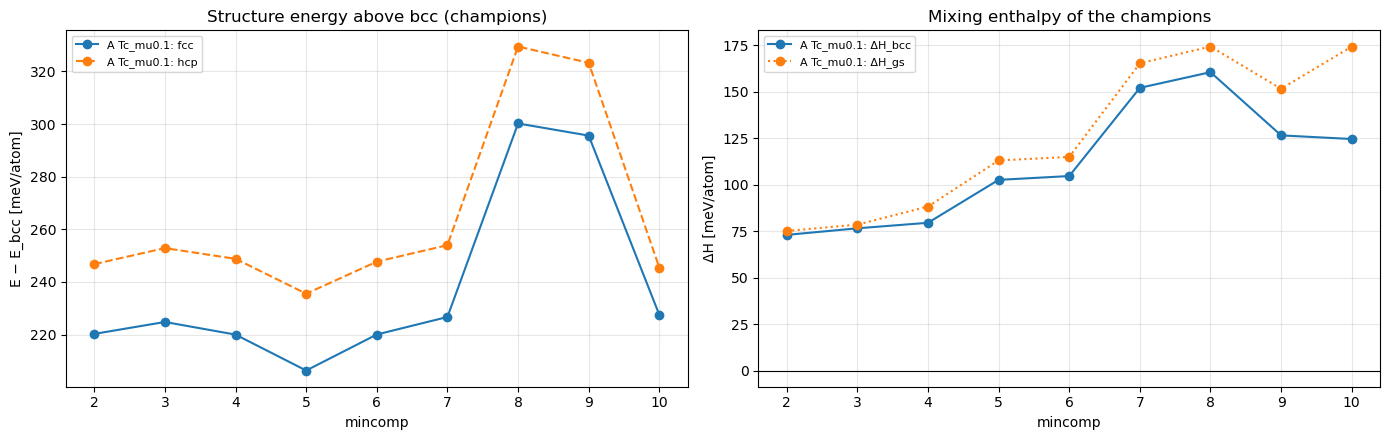

In [20]:
TD = champions_td('A_mu0.1', champ)
display(REF.loc[ELEMENTS].style.format(REF_FMT, na_rep='—').set_caption('Pure-element references (Topola, same settings)'))
display(TD.style.format(TD_FMT, na_rep='—').set_caption('Champions, set A, Tc_mu0.1'))
td_plot({'A Tc_mu0.1': TD})

**Observations.**
- **All 9 champions are bcc,** with fcc 206–300 and hcp 236–330 meV/atom above bcc. For pure Nb the gap is 393 and 417 meV.
  The bcc lattice of the champions is therefore not in question within this model.
- **ΔH_bcc is positive:** +73 meV for Nb59Zr41 (mc2), +77 to +105 meV for mc3–mc6, +152 and +160 meV for mc7 and mc8
  (Y enters), and +126 and +124 meV for mc9 and mc10.
- **Element references:** taking the ground state instead of bcc adds 2–14 meV for mc2–mc8, 25 meV for mc9 and 50 meV
  for mc10 (Ru and Re, hcp far below bcc). Ti, Hf and Y enter the champions at
  only 5–8 %, and for Zr the KKR bcc–hcp difference is only 5 meV. The Y bcc minimum lies outside the scanned lattice range
  (extrapolated), but its energy agrees with `ebulk` to 2 meV.
- **mc9, mc10 (with W and Re):** ΔH is lower than for mc8 although more elements are present. A local test for mc10
  (bcc, 3 lattice constants) gives ΔH = +124 meV, +157 without Ru, +152 without Re and +187 without both: Ru and Re lower
  ΔH by about 60 meV (strong bonding with Zr, Hf, Ti, Y).

## 14. Conclusions (final data, copied 2026-11-01; all 15 runs early-stopped)

**Status.** All 15 runs ended by early stop (patience 15). mc6 and mc7 β = 0/1/10 lost iteration 30 (OOM-killed jobs before
the fix e690490); after the fix mc6, mc7 β = 1/2/10 were resumed and ran to 48, 41, 44 and 55 iterations without further
problems. Only two champions changed with the extra iterations: mc6 13.34 → 13.52 K (found in iteration 33) and
mc7 β = 10 11.63 → 11.98 K (iteration 40).

**1. Same basin as before: Nb–Zr (Nb/(Nb+Zr) ≈ 0.6–0.75), VEC ≈ 4.6.** The champions for mc2–mc7 are practically
the same compositions as in the old A/μ*=0.2 runs (composition distance 0.01–0.09): Nb59Zr41 (old Nb58Zr42),
Nb56Zr39Ta5, Nb56Zr34Hf5Ta5, … (mc6: Nb47Zr33 + Ta, Hf, Mo, Ti at 5 %, old Nb59Zr21 + Ta, Hf, Ti, Y; distance 0.18). Forced extra elements again sit at the 5 % floor in the same order
Ti/Ta/Hf → Y → Mo → W; Re and Ru appear only when unavoidable (mc9, mc10).

**2. Tc vs number of elements is unchanged — even in absolute numbers.** Best at ≥ k elements (new / old):
18.99/18.96, 17.92/18.14, 16.60/16.90, 14.99/15.69, 13.52/14.06, 11.92/12.06, 9.73/9.66 K for k = 2..8;
normalised to the binary they agree within 0.04. New: 7.22 K (9 el.) and 4.36 K (10 el.).
The coincidence is not accidental: μ* was calibrated separately for each η definition against the same
literature set, and the GL λ (1.14 for Nb–Zr vs 1.54 in A) is compensated by the lower μ* = 0.1. θ_D is identical
(same mix-Debye), so the drop with k is again entirely in λ (1.14 → 0.54; corr(λ, Tc) = 0.998 over all optimized points).

**3. Differences (minor).**
* mc8: two different compositions are degenerate at 9.7 K — new champion Nb58 + 7 minors (VEC 4.81),
  old Zr35Nb34 (VEC 4.54); the new run's #2 is Nb38Zr30 at 9.64 K, so the landscape at 8 elements is flat
  and the champion choice there is not meaningful.
* mc10 (new): the only case outside the Nb-rich basin — Zr41Nb15 + 8×5 %, i.e. with 50 % forced into minors the
  optimizer prefers Zr as the majority element. Only 3 valid init points existed here.
* Hf/Ta/W enter the champions slightly more often (7/8/3 of 9 champions vs 4/5/1 of 7 before).

**4. Optimizer behaviour unchanged.** 97–100 % `local` points (global only in mc8–10, face points early in mc2/3);
gain over best valid init +0.2 K (mc2, the binary optimum is already in init) to +6 K (mc7–mc8).
The **interior** init (no face/edge points) still reaches the binary/ternary optimum: Nb62Zr38 18.98 K and
Nb57Zr37Ta6 17.79 K vs 18.99 / 17.92 K from the full init, at the cost of ~15 more iterations — the optimizer does find
the edge of the simplex by itself.

**5. β scan (mc7): β irrelevant for the answer, as before.** β = 0/1/2/5/10 → 11.98/11.88/11.92/11.79/11.98 K
(spread 0.2 K), same family Nb50–59 Zr15–24 + 5×5 %. β = 0 (pure exploitation) is as good as β = 2; β = 10 needs the
longest run (champion in iteration 40, 55 iterations) and has the noisiest batches (MAE 0.39 vs 0.23–0.25 K for β ≤ 2).
Surrogate σ is well calibrated for β ≥ 2 (59–62 % within 1σ), overconfident at β ≤ 1 (44–45 %).

**6. Surrogate.** Bias is positive everywhere (KKR > prediction), largest in mc2 (+1.3 K, the narrow binary regime) and
decreasing with mincomp (+0.04 K at mc10). Same sign as in the old runs.

**Bottom line.** Switching η to G-mode + Lloyd normalisation (with the recalibrated μ* = 0.1) does **not** change any
conclusion of the optimization: same Nb–Zr basin, same champion compositions, same ~1–2 K loss per added element,
same purely local character of the search. The GL change matters for the validation against the literature
baseline (GL μ*=0.1: median ratio 1.05, MAE 1.4 K, τ 0.66; old A μ*=0.2: MAE 1.9 K, τ 0.72), not for the ranking of
compositions in the optimizer. Absolute values remain
optimistic: the predicted Nb–Zr optimum (19 K, Zr ≈ 40 %) still lies well above experiment (~11 K near Nb75Zr25).